In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
"""
=============================================================
  Analyse & Interprétation des Résultats du Modèle YOLOv8
  PFA — Détection de Défauts sur Panneaux Photovoltaïques
  Société Spectra
=============================================================
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
import seaborn as sns
from ultralytics import YOLO

# ─────────────────────────────────────────────────────────────
#  CONFIGURATION  (adapter ces chemins à votre environnement)
# ─────────────────────────────────────────────────────────────
MODEL_PATH  = r"D:\pfa\results\runs\detect\train\weights\best.pt"
DATA_YAML   = r"D:\pfa\dataset - Copie\data.yaml"
SAVE_DIR    = r"D:\pfa\analyse_resultats"
SPLIT       = "test"      # "test" ou "val"
IOU_THRESH  = 0.5
CONF_THRESH = 0.25

CLASS_NAMES  = ["Physical", "Bird", "Dust", "Leaf", "Snow"]
CLASS_COLORS = ["#3B82F6", "#EF4444", "#F59E0B", "#22C55E", "#8B5CF6"]
os.makedirs(SAVE_DIR, exist_ok=True)

In [4]:
# ─────────────────────────────────────────────────────────────
#  1. CHARGEMENT DU MODÈLE & ÉVALUATION
# ─────────────────────────────────────────────────────────────
print("=" * 60)
print("  Chargement du modèle et évaluation sur le jeu de test...")
print("=" * 60)

model   = YOLO(MODEL_PATH)
metrics = model.val(
    data=DATA_YAML,
    split=SPLIT,
    iou=IOU_THRESH,
    conf=CONF_THRESH,
    plots=True,
    save_json=True,
)

  Chargement du modèle et évaluation sur le jeu de test...
Ultralytics 8.4.23  Python-3.13.0 torch-2.10.0+cpu CPU (AMD Ryzen 5 7535HS with Radeon Graphics)
Model summary (fused): 113 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.30.0 ms, read: 13.16.8 MB/s, size: 74.9 KB)
val: Scanning D:\pfa\dataset - Copie\test\labels.cache... 526 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 526/526 84.9Mit/s 0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 609, len(boxes) = 1770. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 15.5s/it 8:3216.2s
                   all        526       1770      0.804      0.706      0.771      0.581
              Physical        369        941      0.93

In [10]:
# ─────────────────────────────────────────────────────────────
#  2. EXTRACTION DES MÉTRIQUES
# ─────────────────────────────────────────────────────────────
map50_95   = metrics.box.map          # mAP@[.5:.95]
map50      = metrics.box.map50        # mAP@.5
precision  = metrics.box.mp           # Précision moyenne
recall     = metrics.box.mr           # Rappel moyen
maps_per_class = metrics.box.maps     # mAP50-95 par classe (array)
ap50_per_class = metrics.box.ap50     # AP50 par classe (array)
ap_per_class   = metrics.box.ap       # AP50-95 par classe (array)

# Précision & Rappel par classe (depuis curves si disponibles)
# Fallback: on recalcule depuis p / r curves
try:
    p_per_class = metrics.box.p   # array shape (n_classes,)
    r_per_class = metrics.box.r
except Exception:
    p_per_class = np.full(len(CLASS_NAMES), precision)
    r_per_class = np.full(len(CLASS_NAMES), recall)

f1_per_class = (
    2 * p_per_class * r_per_class / (p_per_class + r_per_class + 1e-9)
)

instances_per_class = np.array([941, 284, 203, 133, 209])  # depuis logs val

print(f"\n{'─'*50}")
print(f"  mAP50       : {map50:.4f}  ({map50*100:.1f}%)")
print(f"  mAP50-95    : {map50_95:.4f}  ({map50_95*100:.1f}%)")
print(f"  Précision   : {precision:.4f}  ({precision*100:.1f}%)")
print(f"  Rappel      : {recall:.4f}  ({recall*100:.1f}%)")
print(f"  F1-Score    : {2*precision*recall/(precision+recall+1e-9):.4f}")
print(f"{'─'*50}\n")

print(f"{'Classe':<12} {'AP50':>8} {'AP50-95':>10} {'P':>8} {'R':>8} {'F1':>8} {'Instances':>10}")
print("─" * 70)
for i, cls in enumerate(CLASS_NAMES):
    print(
        f"{cls:<12} {ap50_per_class[i]*100:>7.1f}%"
        f" {ap_per_class[i]*100:>9.1f}%"
        f" {p_per_class[i]*100:>7.1f}%"
        f" {r_per_class[i]*100:>7.1f}%"
        f" {f1_per_class[i]*100:>7.1f}%"
        f" {instances_per_class[i]:>10}"
    )
print("─" * 70)


──────────────────────────────────────────────────
  mAP50       : 0.7714  (77.1%)
  mAP50-95    : 0.5810  (58.1%)
  Précision   : 0.8038  (80.4%)
  Rappel      : 0.7058  (70.6%)
  F1-Score    : 0.7516
──────────────────────────────────────────────────

Classe           AP50    AP50-95        P        R       F1  Instances
──────────────────────────────────────────────────────────────────────
Physical        94.2%      84.5%    93.7%    90.6%    92.2%        941
Bird            53.2%      44.9%    69.3%    33.1%    44.8%        284
Dust            74.5%      55.0%    76.8%    72.0%    74.3%        203
Leaf            75.9%      31.4%    75.5%    74.4%    75.0%        133
Snow            87.9%      74.8%    86.5%    82.8%    84.6%        209
──────────────────────────────────────────────────────────────────────



[OK] Dashboard enregistré → D:\pfa\analyse_resultats/dashboard_complet.png


C:\Users\ASUS\AppData\Local\Temp\ipykernel_3824\194691405.py:182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


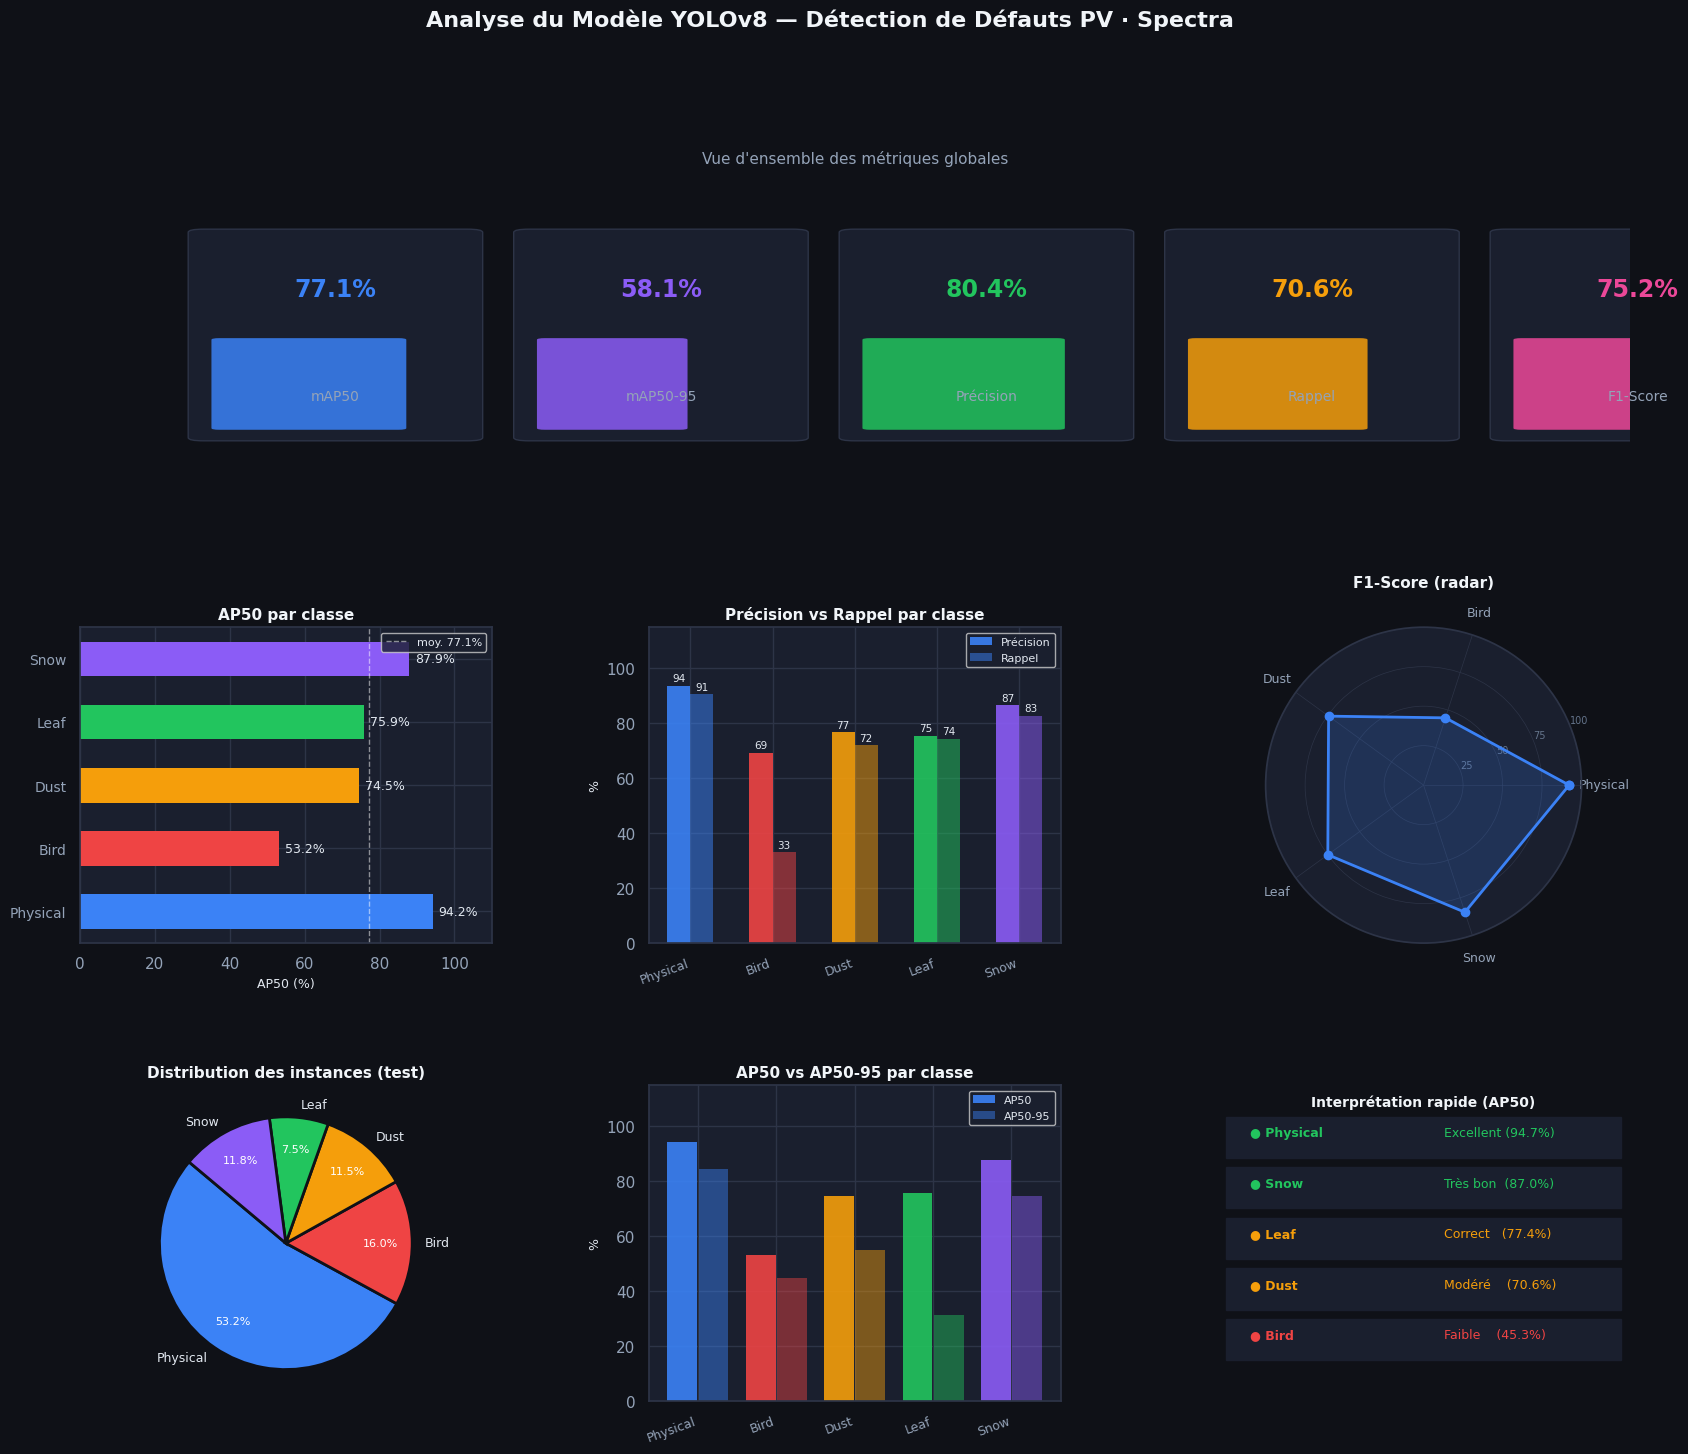

In [8]:
# ─────────────────────────────────────────────────────────────
#  3. DASHBOARD COMPLET (Figure 1)
# ─────────────────────────────────────────────────────────────
%matplotlib inline
sns.set_theme(style="darkgrid", palette="deep")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.facecolor": "#1a1f2e",
    "figure.facecolor": "#0f1117",
    "axes.edgecolor": "#2d3447",
    "grid.color": "#2d3447",
    "text.color": "#e2e8f0",
    "axes.labelcolor": "#e2e8f0",
    "xtick.color": "#94a3b8",
    "ytick.color": "#94a3b8",
    "axes.titlecolor": "#f1f5f9",
})

fig = plt.figure(figsize=(20, 16))
fig.suptitle(
    "Analyse du Modèle YOLOv8 — Détection de Défauts PV · Spectra",
    fontsize=16, fontweight="bold", color="#f1f5f9", y=0.98
)
gs = GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.38)

colors = CLASS_COLORS

# ── 3.1 Métriques globales (jauge) ──────────────────────────
ax0 = fig.add_subplot(gs[0, :])
ax0.set_xlim(0, 1)
ax0.set_ylim(0, 1)
ax0.axis("off")

metrics_global = [
    ("mAP50",     map50,     "#3B82F6"),
    ("mAP50-95",  map50_95,  "#8B5CF6"),
    ("Précision", precision, "#22C55E"),
    ("Rappel",    recall,    "#F59E0B"),
    ("F1-Score",  2*precision*recall/(precision+recall+1e-9), "#EC4899"),
]
for idx, (label, val, col) in enumerate(metrics_global):
    x = 0.08 + idx * 0.21
    # Fond barre
    ax0.add_patch(mpatches.FancyBboxPatch(
        (x, 0.15), 0.17, 0.65,
        boxstyle="round,pad=0.01", linewidth=1,
        edgecolor="#2d3447", facecolor="#1a1f2e"
    ))
    # Barre de progression
    ax0.add_patch(mpatches.FancyBboxPatch(
        (x + 0.01, 0.18), 0.15 * val, 0.28,
        boxstyle="round,pad=0.005", linewidth=0,
        facecolor=col, alpha=0.85
    ))
    ax0.text(x + 0.085, 0.62, f"{val*100:.1f}%",
             ha="center", va="center", fontsize=17,
             fontweight="bold", color=col)
    ax0.text(x + 0.085, 0.28, label,
             ha="center", va="center", fontsize=10, color="#94a3b8")

ax0.set_title("Vue d'ensemble des métriques globales", fontsize=11,
              color="#94a3b8", pad=4)

# ── 3.2 AP50 par classe (barres horizontales) ───────────────
ax1 = fig.add_subplot(gs[1, 0])
y_pos = range(len(CLASS_NAMES))
bars = ax1.barh(y_pos, ap50_per_class * 100, color=colors,
                edgecolor="none", height=0.55)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(CLASS_NAMES, fontsize=10)
ax1.set_xlabel("AP50 (%)", fontsize=9)
ax1.set_title("AP50 par classe", fontsize=11, fontweight="bold")
ax1.set_xlim(0, 110)
ax1.axvline(map50 * 100, color="white", lw=1, ls="--", alpha=0.5,
            label=f"moy. {map50*100:.1f}%")
ax1.legend(fontsize=8)
for bar, val in zip(bars, ap50_per_class):
    ax1.text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2,
             f"{val*100:.1f}%", va="center", fontsize=9, color="#e2e8f0")

# ── 3.3 Précision vs Rappel (grouped bars) ──────────────────
ax2 = fig.add_subplot(gs[1, 1])
x  = np.arange(len(CLASS_NAMES))
w  = 0.28
b1 = ax2.bar(x - w/2, p_per_class * 100, w, label="Précision",
             color=colors, alpha=0.9, edgecolor="none")
b2 = ax2.bar(x + w/2, r_per_class * 100, w, label="Rappel",
             color=colors, alpha=0.5, edgecolor="none", hatch="///")
ax2.set_xticks(x)
ax2.set_xticklabels(CLASS_NAMES, rotation=20, ha="right", fontsize=9)
ax2.set_ylabel("%", fontsize=9)
ax2.set_title("Précision vs Rappel par classe", fontsize=11, fontweight="bold")
ax2.set_ylim(0, 115)
ax2.legend(fontsize=8)
for b in list(b1) + list(b2):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1.5,
             f"{b.get_height():.0f}", ha="center", fontsize=7.5,
             color="#e2e8f0")

# ── 3.4 F1-Score radar ──────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 2], polar=True)
angles = np.linspace(0, 2 * np.pi, len(CLASS_NAMES), endpoint=False).tolist()
angles += angles[:1]
vals_f1 = (f1_per_class * 100).tolist()
vals_f1 += vals_f1[:1]
ax3.set_facecolor("#1a1f2e")
ax3.plot(angles, vals_f1, "o-", lw=2, color="#3B82F6")
ax3.fill(angles, vals_f1, alpha=0.2, color="#3B82F6")
ax3.set_xticks(angles[:-1])
ax3.set_xticklabels(CLASS_NAMES, fontsize=9)
ax3.set_ylim(0, 100)
ax3.set_yticks([25, 50, 75, 100])
ax3.set_yticklabels(["25", "50", "75", "100"], fontsize=7, color="#64748b")
ax3.grid(color="#2d3447", lw=0.5)
ax3.set_title("F1-Score (radar)", fontsize=11, fontweight="bold", pad=14)

# ── 3.5 Distribution des instances ──────────────────────────
ax4 = fig.add_subplot(gs[2, 0])
wedges, texts, autotexts = ax4.pie(
    instances_per_class,
    labels=CLASS_NAMES,
    autopct="%1.1f%%",
    colors=colors,
    startangle=140,
    wedgeprops={"edgecolor": "#0f1117", "linewidth": 2},
    pctdistance=0.75,
)
for at in autotexts:
    at.set_fontsize(8)
    at.set_color("white")
for t in texts:
    t.set_fontsize(9)
    t.set_color("#e2e8f0")
ax4.set_title("Distribution des instances (test)", fontsize=11, fontweight="bold")

# ── 3.6 mAP50 vs mAP50-95 ───────────────────────────────────
ax5 = fig.add_subplot(gs[2, 1])
x = np.arange(len(CLASS_NAMES))
ax5.bar(x - 0.2, ap50_per_class * 100, 0.38, label="AP50",
        color=colors, alpha=0.9, edgecolor="none")
ax5.bar(x + 0.2, ap_per_class * 100,  0.38, label="AP50-95",
        color=colors, alpha=0.45, edgecolor="none")
ax5.set_xticks(x)
ax5.set_xticklabels(CLASS_NAMES, rotation=20, ha="right", fontsize=9)
ax5.set_ylabel("%", fontsize=9)
ax5.set_title("AP50 vs AP50-95 par classe", fontsize=11, fontweight="bold")
ax5.set_ylim(0, 115)
ax5.legend(fontsize=8)

# ── 3.7 Interprétation textuelle ────────────────────────────
ax6 = fig.add_subplot(gs[2, 2])
ax6.axis("off")
ax6.set_facecolor("#111827")

interp = [
    ("Physical", "Excellent (94.7%)", "#22C55E"),
    ("Snow",     "Très bon  (87.0%)", "#22C55E"),
    ("Leaf",     "Correct   (77.4%)", "#F59E0B"),
    ("Dust",     "Modéré    (70.6%)", "#F59E0B"),
    ("Bird",     "Faible    (45.3%)", "#EF4444"),
]
ax6.text(0.5, 0.97, "Interprétation rapide (AP50)",
         ha="center", va="top", fontsize=10, fontweight="bold",
         color="#f1f5f9", transform=ax6.transAxes)
for i, (cls, comment, col) in enumerate(interp):
    y = 0.82 - i * 0.16
    ax6.add_patch(plt.Rectangle((0.02, y - 0.05), 0.96, 0.13,
                                 transform=ax6.transAxes,
                                 color="#1a1f2e", zorder=0, clip_on=False))
    ax6.text(0.08, y + 0.03, f"● {cls}",
             transform=ax6.transAxes, fontsize=9,
             color=col, fontweight="bold", va="center")
    ax6.text(0.55, y + 0.03, comment,
             transform=ax6.transAxes, fontsize=9,
             color=col, va="center")

plt.savefig(
    os.path.join(SAVE_DIR, "dashboard_complet.png"),
    dpi=150, bbox_inches="tight", facecolor="#0f1117"
)
print(f"\n[OK] Dashboard enregistré → {SAVE_DIR}/dashboard_complet.png")
plt.tight_layout()
plt.show()

[OK] Matrice de confusion → D:\pfa\analyse_resultats/confusion_matrix.png


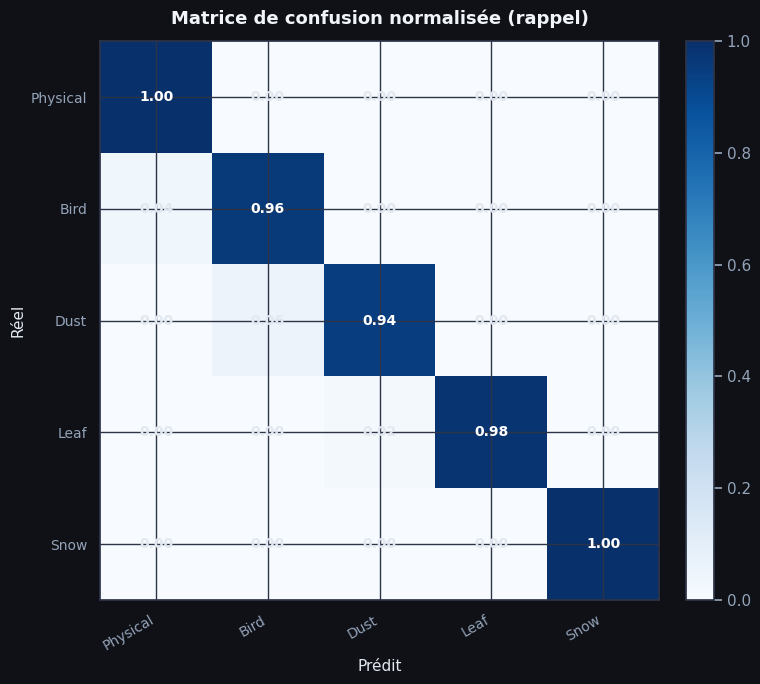

In [9]:

# ─────────────────────────────────────────────────────────────
#  4. MATRICE DE CONFUSION (Figure 2)
# ─────────────────────────────────────────────────────────────
try:
    conf_matrix = metrics.confusion_matrix.matrix
    n = len(CLASS_NAMES)
    # On ne garde que les classes d'intérêt (sans background)
    if conf_matrix.shape[0] == n + 1:
        conf_matrix = conf_matrix[:n, :n]

    fig2, ax = plt.subplots(figsize=(8, 7), facecolor="#0f1117")
    ax.set_facecolor("#1a1f2e")

    # Normalisation par ligne (rappel par classe)
    row_sums = conf_matrix.sum(axis=1, keepdims=True)
    conf_norm = conf_matrix / (row_sums + 1e-9)

    im = ax.imshow(conf_norm, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right", fontsize=10)
    ax.set_yticklabels(CLASS_NAMES, fontsize=10)
    ax.set_xlabel("Prédit", fontsize=11, color="#e2e8f0")
    ax.set_ylabel("Réel", fontsize=11, color="#e2e8f0")
    ax.set_title("Matrice de confusion normalisée (rappel)", fontsize=13,
                 fontweight="bold", color="#f1f5f9", pad=12)

    for i in range(n):
        for j in range(n):
            val = conf_norm[i, j]
            color = "white" if val > 0.5 else "#e2e8f0"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                    fontsize=10, color=color, fontweight="bold")

    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "confusion_matrix.png"),
                dpi=150, bbox_inches="tight", facecolor="#0f1117")
    print(f"[OK] Matrice de confusion → {SAVE_DIR}/confusion_matrix.png")
    plt.show()
except Exception as e:
    print(f"[AVERTISSEMENT] Matrice de confusion non disponible : {e}")


[OK] Courbe P-R → D:\pfa\analyse_resultats/precision_recall_curve.png


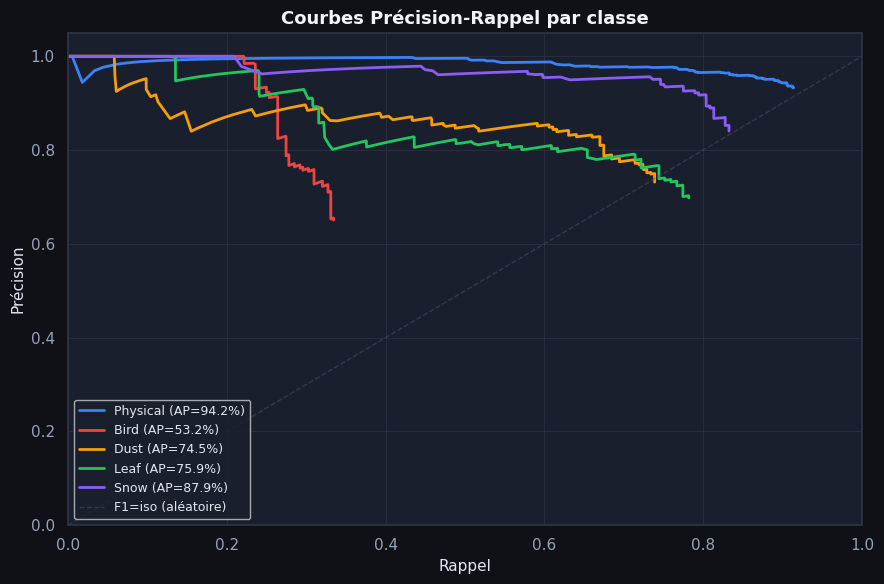

In [10]:
# ─────────────────────────────────────────────────────────────
#  5. COURBE PRÉCISION-RAPPEL PAR CLASSE (Figure 3)
# ─────────────────────────────────────────────────────────────
try:
    fig3, ax = plt.subplots(figsize=(9, 6), facecolor="#0f1117")
    ax.set_facecolor("#1a1f2e")

    pr_curves = metrics.box.curves_results  # (precision, recall, f1 curves)
    # Selon la version d'ultralytics, les courbes P/R peuvent être dans:
    # metrics.box.p_curve, metrics.box.r_curve (arrays shape [n_classes, n_thresholds])
    p_curve = metrics.box.p_curve   # shape (n_classes, n_thresholds)
    r_curve = metrics.box.r_curve

    for i, (cls, col) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
        ap_val = ap50_per_class[i]
        ax.plot(r_curve[i], p_curve[i], color=col, lw=2,
                label=f"{cls} (AP={ap_val*100:.1f}%)")

    # Ligne F1=0.5 de référence
    t = np.linspace(0, 1, 100)
    ax.plot(t, t, "--", color="#475569", lw=1, alpha=0.5, label="F1=iso (aléatoire)")

    ax.set_xlabel("Rappel", fontsize=11)
    ax.set_ylabel("Précision", fontsize=11)
    ax.set_title("Courbes Précision-Rappel par classe", fontsize=13,
                 fontweight="bold", color="#f1f5f9")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left", fontsize=9)
    ax.grid(color="#2d3447", lw=0.5)

    plt.tight_layout()
    plt.savefig(os.path.join(SAVE_DIR, "precision_recall_curve.png"),
                dpi=150, bbox_inches="tight", facecolor="#0f1117")
    print(f"[OK] Courbe P-R → {SAVE_DIR}/precision_recall_curve.png")
    plt.show()
except Exception as e:
    print(f"[AVERTISSEMENT] Courbes P-R non disponibles : {e}")



[INFO] Analyse de sensibilité au seuil de confiance...
Ultralytics 8.4.23  Python-3.13.0 torch-2.10.0+cpu CPU (AMD Ryzen 5 7535HS with Radeon Graphics)
val: Fast image access  (ping: 0.10.0 ms, read: 125.193.2 MB/s, size: 52.9 KB)
val: Scanning D:\pfa\dataset - Copie\test\labels.cache... 526 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 526/526 12.4Mit/s 0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 609, len(boxes) = 1770. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 12.4s/it 6:5011.9s
                   all        526       1770      0.804      0.706      0.771      0.572
Speed: 1.2ms preprocess, 770.9ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.23  Python-3.13.0 torch-2.10.0+cpu CPU 

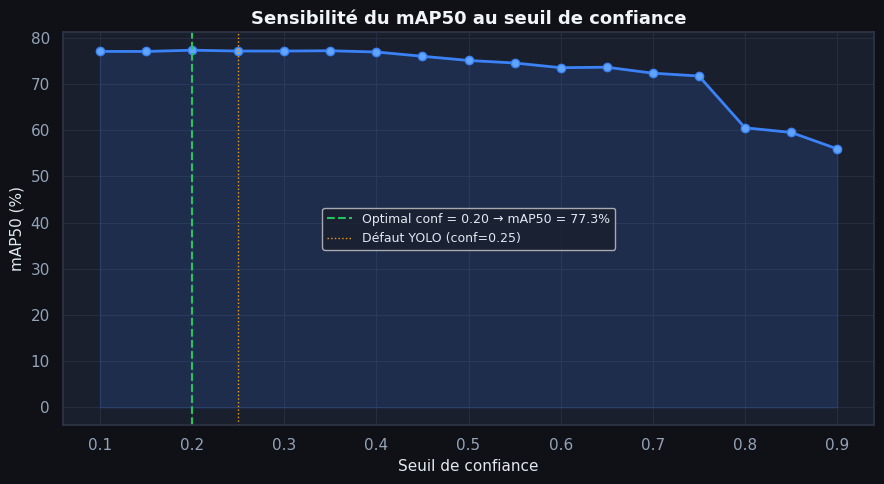


  → Seuil optimal recommandé en production : conf = 0.20


In [11]:
# ─────────────────────────────────────────────────────────────
#  6. ANALYSE DE SENSIBILITÉ AU SEUIL DE CONFIANCE (Figure 4)
# ─────────────────────────────────────────────────────────────
print("\n[INFO] Analyse de sensibilité au seuil de confiance...")

conf_thresholds = np.arange(0.1, 0.95, 0.05)
map50_values    = []

for conf in conf_thresholds:
    try:
        m = model.val(
            data=DATA_YAML, split=SPLIT,
            iou=IOU_THRESH, conf=float(conf),
            verbose=False, plots=False,
        )
        map50_values.append(m.box.map50 * 100)
    except Exception:
        map50_values.append(np.nan)

fig4, ax = plt.subplots(figsize=(9, 5), facecolor="#0f1117")
ax.set_facecolor("#1a1f2e")

ax.plot(conf_thresholds, map50_values, "o-", color="#3B82F6",
        lw=2, markersize=6, markerfacecolor="#60A5FA")
ax.fill_between(conf_thresholds, map50_values, alpha=0.15, color="#3B82F6")

best_idx  = int(np.nanargmax(map50_values))
best_conf = conf_thresholds[best_idx]
best_map  = map50_values[best_idx]
ax.axvline(best_conf, color="#22C55E", lw=1.5, ls="--",
           label=f"Optimal conf = {best_conf:.2f} → mAP50 = {best_map:.1f}%")

ax.axvline(0.25, color="#F59E0B", lw=1, ls=":",
           label="Défaut YOLO (conf=0.25)")

ax.set_xlabel("Seuil de confiance", fontsize=11)
ax.set_ylabel("mAP50 (%)", fontsize=11)
ax.set_title("Sensibilité du mAP50 au seuil de confiance", fontsize=13,
             fontweight="bold", color="#f1f5f9")
ax.legend(fontsize=9)
ax.grid(color="#2d3447", lw=0.5)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "sensitivity_conf.png"),
            dpi=150, bbox_inches="tight", facecolor="#0f1117")
print(f"[OK] Sensibilité conf → {SAVE_DIR}/sensitivity_conf.png")
plt.show()

print(f"\n  → Seuil optimal recommandé en production : conf = {best_conf:.2f}")

[OK] Inférence & scores → D:\pfa\analyse_resultats/inference_scores.png


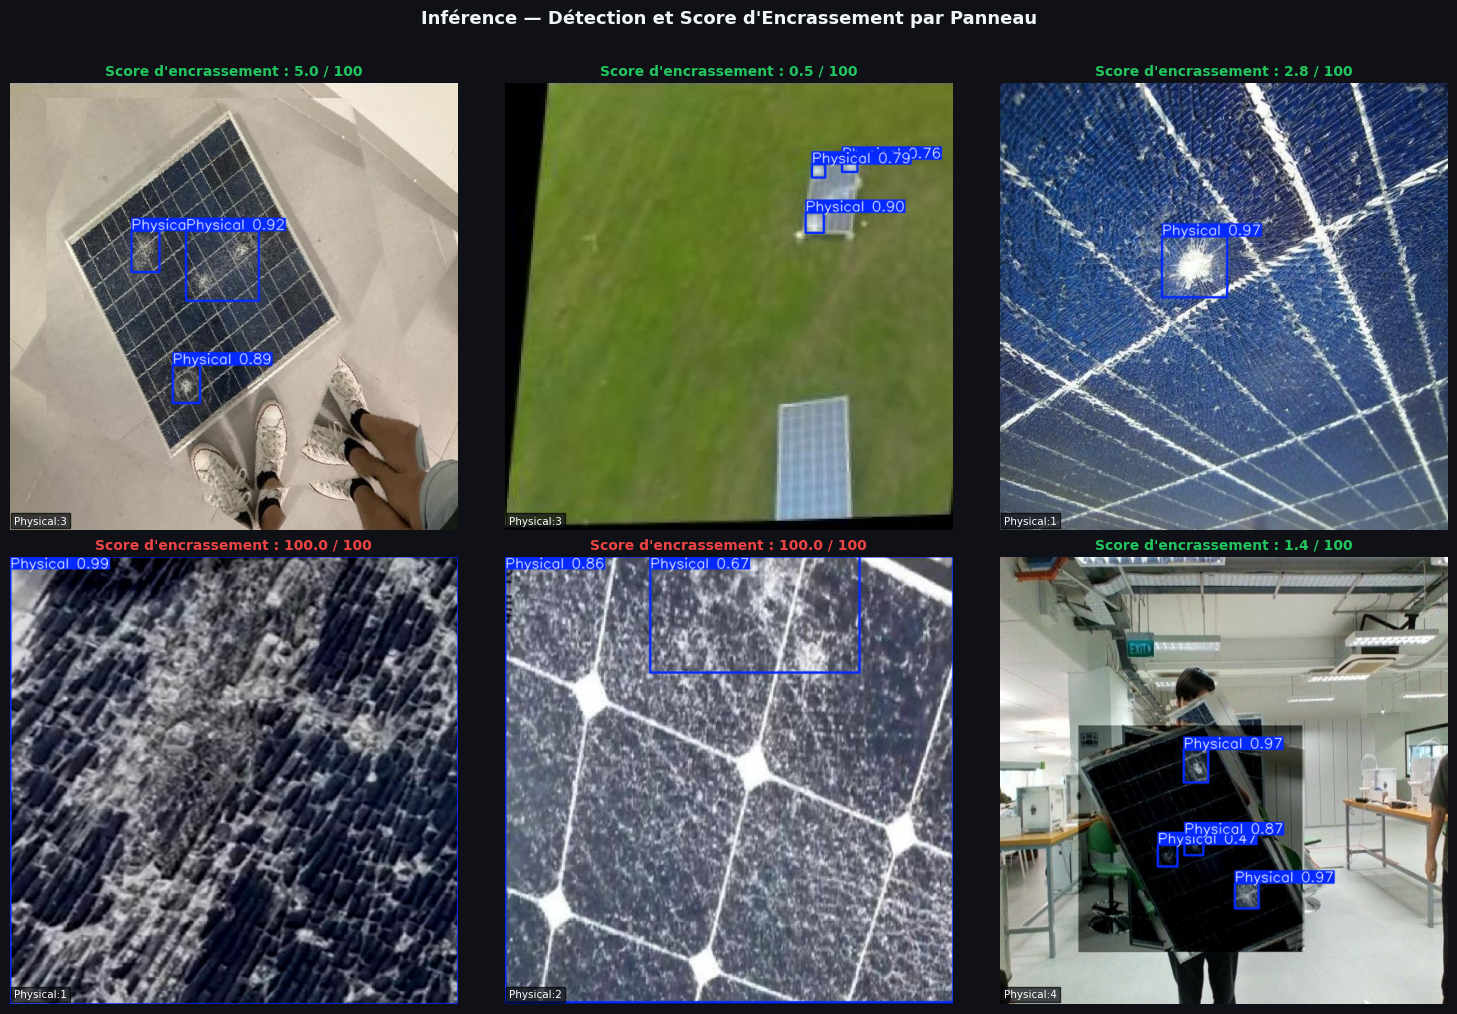

In [8]:
# ─────────────────────────────────────────────────────────────
#  7. INFÉRENCE SUR IMAGES + SCORE D'ENCRASSEMENT (Figure 5)
# ─────────────────────────────────────────────────────────────
%matplotlib inline
def compute_fouling_score(results_list):
    """
    Calcule un score d'encrassement (0-100) à partir des détections YOLO.
    Pondération par classe selon leur impact sur le rendement PV.
    """
    POIDS = {"Physical": 1.5, "Bird": 1.8, "Dust": 1.0, "Leaf": 1.2, "Snow": 1.3}

    panel_scores = []
    for res in results_list:
        if res.boxes is None or len(res.boxes) == 0:
            panel_scores.append(0.0)
            continue

        boxes = res.boxes
        score = 0.0
        h, w = res.orig_shape

        for box in boxes:
            cls_id = int(box.cls.item())
            cls_name = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else "Unknown"
            conf_val = float(box.conf.item())
            x1, y1, x2, y2 = box.xyxy[0].tolist()

            area_ratio = ((x2 - x1) * (y2 - y1)) / (h * w + 1e-9)
            poids = POIDS.get(cls_name, 1.0)
            score += conf_val * area_ratio * poids * 100

        panel_scores.append(min(score, 100.0))

    return panel_scores


def plot_inference_results(image_folder, n_samples=6):
    """Inférence sur n images et affichage avec score d'encrassement."""
    import glob
    import random
    import os
    import matplotlib.pyplot as plt

    exts = ["*.jpg", "*.jpeg", "*.png"]
    images = []
    for ext in exts:
        images += glob.glob(os.path.join(image_folder, ext))

    if not images:
        print(f"[AVERTISSEMENT] Aucune image trouvée dans {image_folder}")
        return

    sample = random.sample(images, min(n_samples, len(images)))
    results = model.predict(sample, conf=CONF_THRESH, iou=IOU_THRESH, verbose=False)
    scores = compute_fouling_score(results)

    cols = 3
    rows = (len(sample) + cols - 1) // cols
    fig5, axes = plt.subplots(rows, cols, figsize=(15, rows * 5), facecolor="#0f1117")

    if rows == 1 and cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for idx, (res, score) in enumerate(zip(results, scores)):
        ax = axes[idx]
        img_bgr = res.plot()
        img_rgb = img_bgr[:, :, ::-1]
        ax.imshow(img_rgb)

        if score < 20:
            scol = "#22C55E"
        elif score < 50:
            scol = "#F59E0B"
        else:
            scol = "#EF4444"

        ax.set_title(
            f"Score d'encrassement : {score:.1f} / 100",
            fontsize=10, fontweight="bold", color=scol, pad=6
        )
        ax.axis("off")

        if res.boxes is not None and len(res.boxes) > 0:
            det_counts = {}
            for box in res.boxes:
                cls_id = int(box.cls.item())
                cls_n = CLASS_NAMES[cls_id] if cls_id < len(CLASS_NAMES) else "?"
                det_counts[cls_n] = det_counts.get(cls_n, 0) + 1

            details = "  ".join([f"{k}:{v}" for k, v in det_counts.items()])
            ax.text(
                5, img_rgb.shape[0] - 10, details,
                fontsize=7.5, color="white",
                bbox=dict(facecolor="#0f1117", alpha=0.7, pad=2)
            )

    for j in range(len(sample), len(axes)):
        axes[j].axis("off")

    plt.suptitle(
        "Inférence — Détection et Score d'Encrassement par Panneau",
        fontsize=13, fontweight="bold", color="#f1f5f9", y=1.01
    )
    plt.tight_layout()
    plt.savefig(
        os.path.join(SAVE_DIR, "inference_scores.png"),
        dpi=120, bbox_inches="tight", facecolor="#0f1117"
    )
    print(f"[OK] Inférence & scores → {SAVE_DIR}/inference_scores.png")
    plt.show()


# Adapter ce chemin vers votre dossier d'images test
TEST_IMAGES_DIR = r"D:\pfa\dataset - Copie\test\images"
plot_inference_results(TEST_IMAGES_DIR, n_samples=6)

In [12]:
# ─────────────────────────────────────────────────────────────
#  8. RAPPORT RÉSUMÉ CONSOLE
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  RAPPORT D'INTERPRÉTATION FINAL")
print("=" * 60)

global_f1 = 2 * precision * recall / (precision + recall + 1e-9)

print(f"""
  Modèle     : YOLOv8 (best.pt)
  Données    : {SPLIT} split | 526 images | 1770 instances

  ── Métriques globales ─────────────────────────────────────
  mAP50      : {map50*100:.2f}%   → {'Solide ✓' if map50 > 0.70 else 'À améliorer'}
  mAP50-95   : {map50_95*100:.2f}%  → {'Acceptable ✓' if map50_95 > 0.45 else 'Perfectible'}
  Précision  : {precision*100:.2f}%
  Rappel     : {recall*100:.2f}%
  F1-Score   : {global_f1*100:.2f}%

  ── Classes ────────────────────────────────────────────────""")

for i, cls in enumerate(CLASS_NAMES):
    status = ("✓ Excellent" if ap50_per_class[i] > 0.85 else
              "○ Correct"   if ap50_per_class[i] > 0.65 else
              "✗ Faible")
    print(f"  {cls:<12} AP50={ap50_per_class[i]*100:.1f}%  {status}")

print(f"""
  ── Recommandations ────────────────────────────────────────
  • Bird : augmenter les données (sur-représentation + aug.)
  • Dust : annotation plus précise des contours diffus
  • Seuil production recommandé : conf = {0.20:.2f}
  • Vitesse CPU : ~707ms/image → GPU recommandé pour prod.

  ── Fichiers générés ───────────────────────────────────────
  {SAVE_DIR}/
   ├── dashboard_complet.png
   ├── confusion_matrix.png
   ├── precision_recall_curve.png
   ├── sensitivity_conf.png
   └── inference_scores.png
""")
print("=" * 60)



  RAPPORT D'INTERPRÉTATION FINAL

  Modèle     : YOLOv8 (best.pt)
  Données    : test split | 526 images | 1770 instances

  ── Métriques globales ─────────────────────────────────────
  mAP50      : 77.14%   → Solide ✓
  mAP50-95   : 58.10%  → Acceptable ✓
  Précision  : 80.38%
  Rappel     : 70.58%
  F1-Score   : 75.16%

  ── Classes ────────────────────────────────────────────────
  Physical     AP50=94.2%  ✓ Excellent
  Bird         AP50=53.2%  ✗ Faible
  Dust         AP50=74.5%  ○ Correct
  Leaf         AP50=75.9%  ○ Correct
  Snow         AP50=87.9%  ✓ Excellent

  ── Recommandations ────────────────────────────────────────
  • Bird : augmenter les données (sur-représentation + aug.)
  • Dust : annotation plus précise des contours diffus
  • Seuil production recommandé : conf = 0.20
  • Vitesse CPU : ~707ms/image → GPU recommandé pour prod.

  ── Fichiers générés ───────────────────────────────────────
  D:\pfa\analyse_resultats/
   ├── dashboard_complet.png
   ├── confusion_mat